# 🍁 Canadian Credit Risk Model — Analysis

Predict loan-default probability for the Canadian banking context (**CAD**, province, **Equifax/TransUnion 300–900 credit score**), calibrate it, explain it with SHAP, and audit it for fairness under the **Canadian Human Rights Act** — aligned to **OSFI Guideline E-23**.

*Data is a public credit-risk dataset adapted to a Canadian framing (see `data/canadianize.py`); a demonstration proxy, not real Canadian bank data (PIPEDA).*

In [ ]:
import pandas as pd, loan_default as L
df = L.engineer_features(L.load_data())
df[['credit_score','person_income','loan_amnt','loan_int_rate']].describe().round(1)

       credit_score  person_income  loan_amnt  loan_int_rate
count       24435.0        24435.0    24435.0        24435.0
mean          728.2        66156.1     9583.8           11.0
std           108.7        65688.5     6330.1            3.1
min           300.0         4000.0      500.0            5.4
25%           665.0        38400.0     5000.0            8.5
50%           758.0        55000.0     8000.0           11.0
75%           810.0        79200.0    12100.0           13.1
max           900.0      6000000.0    35000.0           22.5

### Province mix (sampled from StatsCan population shares)

In [ ]:
df['province'].value_counts(normalize=True).round(3)

province
ON    0.358
QC    0.246
BC    0.138
AB    0.121
MB    0.036
SK    0.030
NS    0.029
NB    0.024
NL    0.014
PE    0.005

## 1. The target is imbalanced

About 1 in 5 loans defaults, so recall and calibration matter more than raw accuracy.

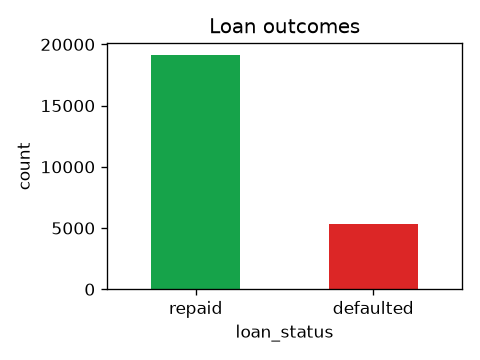

In [ ]:
df['loan_status'].value_counts().plot.bar()

## 2. Held-out performance (calibrated Random Forest)

Metrics on the 20% test set, including **Brier** and **ECE** which measure how well-calibrated the probabilities are (lower = better).

In [ ]:
import json; json.load(open('model_meta.json'))['metrics']

accuracy    0.9259
precision   0.9351
recall      0.7073
f1          0.8054
roc_auc     0.9344
brier       0.06
ece         0.0048

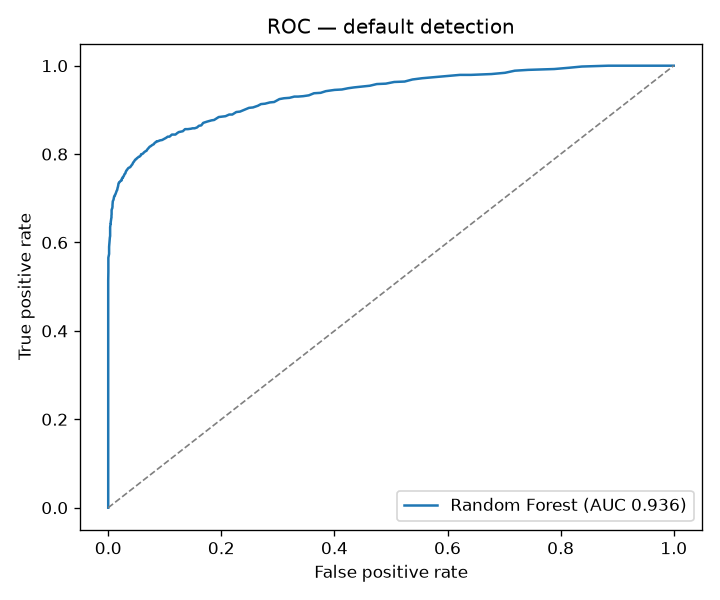

In [ ]:
# ROC on the held-out set
plot_roc(...)

## 3. Calibration — are the probabilities trustworthy?

OSFI E-23 expects sound outputs; a PD feeds IFRS 9 provisioning. The reliability curve shows calibrated predictions track the diagonal.

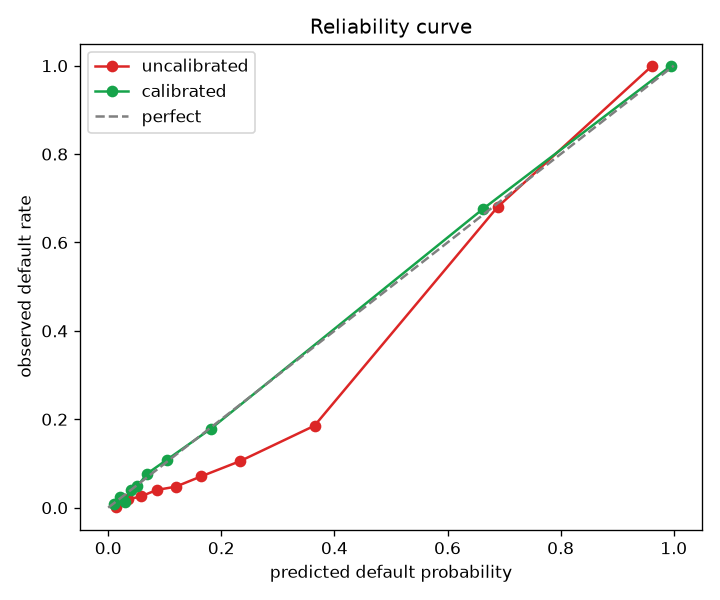

In [ ]:
from calibration import main as calibrate  # Brier/ECE + reliability curve

## 4. Explainability (SHAP)

Which features drive the score — globally, and per applicant for adverse-action reasons. Credit score dominates, as expected.

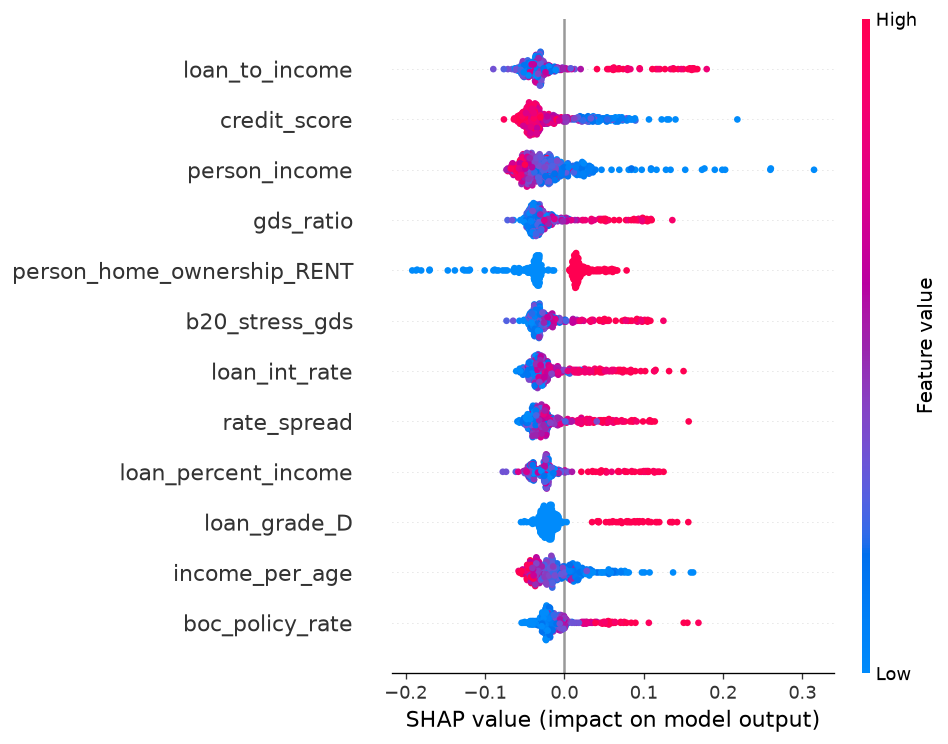

In [ ]:
from explain import save_global_summary

## 5. Cost-based decision threshold

Approving a defaulter loses `principal × LGD`; declining a good borrower loses foregone interest. Because the model is calibrated, the cost-optimal cutoff sits near 0.49.

In [ ]:
from threshold import optimal_threshold
optimal_threshold(scored['actual'], scored['proba'], scored['loan_amnt'], scored['loan_int_rate'])

optimal threshold : 0.46
expected cost     : $1,830,621 CAD
cost at 0.50      : $1,897,816 CAD
saved vs 0.50     : $67,195 CAD

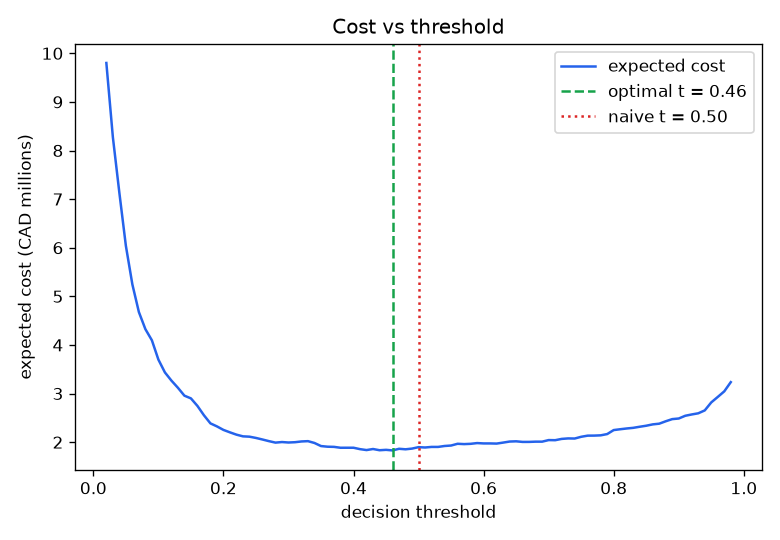

In [ ]:
plot_cost_curve(...)

## 6. Fairness audit (Fairlearn · Canadian Human Rights Act)

Approval parity across **age** (protected ground) and **province**. Both pass the four-fifths rule. No sex/gender field in the data, so that ground is not audited.

In [ ]:
from fairness import group_metrics
group_metrics(scored, 'age_band', t)

age_band      n  approval_rate  default_rate  recall   fpr  approval_ratio 80%_rule
   26-40 2390.0          0.846         0.204   0.682 0.019           0.987       ok
   41-60  203.0          0.857         0.167   0.765 0.018           1.000       ok
     60+    7.0          0.857         0.000   0.000 0.143           1.000       ok
    <=25 2287.0          0.808         0.235   0.764 0.017           0.942       ok

In [ ]:
group_metrics(scored, 'province', t)

province      n  approval_rate  default_rate  recall   fpr  approval_ratio 80%_rule
      AB  554.0          0.841         0.224   0.669 0.012           0.876       ok
      BC  691.0          0.845         0.187   0.744 0.020           0.880       ok
      MB  156.0          0.859         0.141   0.864 0.022           0.895       ok
      NB  130.0          0.915         0.115   0.600 0.017           0.954       ok
      NL   63.0          0.841         0.206   0.769 0.000           0.876       ok
      NS  152.0          0.914         0.132   0.650 0.000           0.953       ok
      ON 1768.0          0.772         0.283   0.735 0.028           0.804       ok
      PE   25.0          0.960         0.080   0.500 0.000           1.000       ok
      QC 1191.0          0.872         0.162   0.731 0.012           0.908       ok
      SK  157.0          0.803         0.255   0.725 0.017           0.836       ok

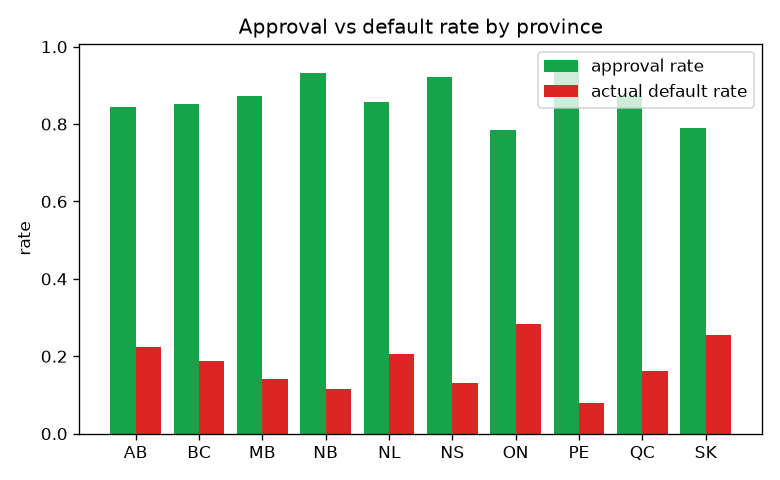

In [ ]:
plot_group_metrics(group_metrics(scored,'province',t), 'province', 'reports/fairness_province.png')

---
**Takeaway.** A calibrated Random Forest reaches ROC AUC ~0.93 with near-zero calibration error, is explainable per decision via SHAP, and passes a Fairlearn fairness screen on age and province — the kind of model-risk evidence OSFI Guideline E-23 expects from a Canadian credit model.